# AQR Momentum Strategies

FINM 36700 HW6: AQR Momentum

Group: Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

FILE = "momentum_data.xlsx"

def load(sheet):
    return pd.read_excel(FILE, sheet_name=sheet, index_col=0, parse_dates=True)

factors = load("factors (excess returns)")
umd     = load("momentum (excess returns)")["UMD"]     # FF momentum
deciles = load("deciles (total returns)")
size    = load("size_sorts (total returns)")
rf      = load("risk-free rate")["RF"]

deciles.columns = [f"D{i}" for i in range(1, 11)]     # D1 = losers, D10 = winners

def stats(r, mkt, hml):
    return pd.Series({
        "Mean":        r.mean() * 12,
        "Vol":         r.std() * np.sqrt(12),
        "Sharpe":      r.mean() / r.std() * np.sqrt(12),
        "Skewness":    r.skew(),
        "Corr to MKT": r.corr(mkt),
        "Corr to HML": r.corr(hml),
    })

FMT = {"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}", "Skewness": "{:.2f}",
       "Corr to MKT": "{:.2f}", "Corr to HML": "{:.2f}"}

---
# 2. Investigating Momentum

Data: `data/momentum_data.xlsx`
- **Tab 1:** momentum factor $\tilde{r}^{\text{mom}}$ and Fama-French momentum $\tilde{r}^{\text{mom:FF}}$
- **Tab 2:** momentum decile portfolios (decile 1 = past losers, decile 10 = past winners)
- **Tab 3:** portfolios sorted on momentum and size: small winners ($r^{\text{momSU}}$), small losers ($r^{\text{momSD}}$), big winners ($r^{\text{momBU}}$), big losers ($r^{\text{momBD}}$)

FF construction:

$$\tilde{r}^{\text{mom:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - \tfrac{1}{2}\left(r^{\text{momBD}} + r^{\text{momSD}}\right)$$

## 2.1 Is momentum still profitable?

Subsamples: 1927–2024, 1927–1993, 1994–2008, 2009–2024.

### (a) 
Fill in Table 1 for $\tilde{r}^{\text{mom:FF}}$ across the four subsamples: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [2]:
periods = {"1927–2024": ("1927", "2024"), "1927–1993": ("1927", "1993"),
           "1994–2008": ("1994", "2008"), "2009–2024": ("2009", "2024")}

table1 = pd.DataFrame({name: stats(umd.loc[a:b], factors["MKT"].loc[a:b], factors["HML"].loc[a:b])
                       for name, (a, b) in periods.items()}).T
table1.style.format(FMT)

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
1927–2024,7.39%,16.27%,0.45,-3.07,-0.35,-0.41
1927–1993,8.81%,16.05%,0.55,-3.91,-0.37,-0.50
1994–2008,10.27%,17.54%,0.59,-0.60,-0.24,-0.12
2009–2024,-1.29%,15.80%,-0.08,-2.69,-0.37,-0.32


### (b) 
Has momentum changed much across the subsamples?

**Answer:**

Yes, but mostly in the return, not the risk. Momentum earned 8.8% a year before 1994 and 10.3% in 1994–2008, so publishing it (Jegadeesh and Titman 1993, Asness 1994) didn't kill it. Then it fell apart: −1.3% a year in 2009–2024, a Sharpe of −0.08. That period starts with the 2009 momentum crash, when the beaten-down losers bounced back hard.

Volatility stayed around 16–18% and the correlations with the market and value stayed negative in every period. So what changed was the premium, not how the strategy behaves.

### (c)
Does the data support AQR's case that momentum belongs in the ideal portfolio? Would it still be valuable if transaction costs pushed mean returns near zero?

In [3]:
# tangency portfolio of MKT, HML and UMD, 1927-2024, with and without UMD, and with UMD's mean set to 0
X = pd.concat([factors[["MKT", "HML"]], umd], axis=1).loc["1927":"2024"]

def tangency(df, mu):
    w = np.linalg.solve(df.cov(), mu)
    w = w / w.sum()
    sharpe = (mu @ w) / np.sqrt(w @ df.cov() @ w) * np.sqrt(12)
    return pd.Series(list(w) + [sharpe], index=list(df.columns) + ["Sharpe"])

mu_zero = X.mean().copy()
mu_zero["UMD"] = 0
pd.DataFrame({"MKT + HML": tangency(X[["MKT", "HML"]], X[["MKT", "HML"]].mean()),
              "MKT + HML + UMD": tangency(X, X.mean()),
              "MKT + HML + UMD (UMD mean = 0)": tangency(X, mu_zero)}).T.round(2)

,HML,MKT,Sharpe,UMD
MKT + HML,0.49,0.51,0.50,NaN
MKT + HML + UMD,0.34,0.25,0.94,0.41
MKT + HML + UMD (UMD mean = 0),0.39,0.35,0.57,0.26


**Answer:**

Yes. Over 1927–2024 momentum has a Sharpe of 0.45 and is negatively correlated with both the market (−0.35) and value (−0.41), so it's a positive premium that also hedges the other two. Adding it to MKT and HML raises the tangency Sharpe from 0.50 to 0.94, and it gets the biggest weight (41%).

It would still help even with a zero mean. Tangency weights depend on Σ⁻¹μ, not just μ, so an asset that moves against MKT and HML still lowers risk. With UMD's mean set to zero it still gets a 26% weight, and the tangency Sharpe is 0.57, still above the 0.50 without it. The catch is crash risk: skewness is −3.1, so the Sharpe ratio makes momentum look safer than it is.

## 2.2 Is a long-only momentum implementation valuable?

Sample: 1994–2024.

Long-only (FF style):

$$\tilde{r}^{\text{momU:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - r^f$$

### (a)
Fill in Table 2 comparing long-short $\tilde{r}^{\text{mom:FF}}$ and long-only $\tilde{r}^{\text{momU:FF}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [4]:
s, e = "1994", "2024"
mkt, hml = factors["MKT"].loc[s:e], factors["HML"].loc[s:e]

long_short = umd.loc[s:e]
long_only  = (0.5 * (size["BIG HiPRIOR"] + size["SMALL HiPRIOR"]) - rf).loc[s:e]   # total returns, so subtract rf

table2 = pd.DataFrame({"Long-short (mom:FF)": stats(long_short, mkt, hml),
                       "Long-only (momU:FF)": stats(long_only, mkt, hml),
                       "MKT": stats(mkt, mkt, hml)}).T
table2.style.format(FMT)

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
Long-short (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31,-0.21
Long-only (momU:FF),11.61%,17.80%,0.65,-0.44,0.90,-0.12
MKT,8.98%,15.54%,0.58,-0.60,1.00,-0.09


In [5]:
# how much of each one is just the market?
def vs_market(r):
    fit = sm.OLS(r, sm.add_constant(mkt)).fit()
    return pd.Series({"alpha (ann.)": fit.params["const"] * 12, "t(alpha)": fit.tvalues["const"],
                      "beta": fit.params["MKT"], "R²": fit.rsquared})

pd.DataFrame({"Long-short": vs_market(long_short), "Long-only": vs_market(long_only)}).T.round(3)

,alpha (ann.),t(alpha),beta,R²
Long-short,0.073,2.521,-0.334,0.096
Long-only,0.023,1.668,1.035,0.817


### (b)
Is long-only momentum as attractive as long-short on mean, volatility and Sharpe ratio?

**Answer:**

On those three numbers alone, long-only actually looks better: an 11.6% mean vs 4.3%, similar volatility (17.8% vs 16.7%) and a Sharpe of 0.65 vs 0.26.

But most of that is just the market. Against MKT, long-only has a beta of 1.04 and an alpha of only 2.3% a year (t = 1.7), while long-short has a beta of −0.33 and an alpha of 7.3% (t = 2.5). So long-only's higher Sharpe comes from owning the market, which you can get cheaply anyway.

### (c)
Is long-only momentum as diversifying against the market and value premia?

**Answer:**

No. Long-only has a 0.90 correlation with the market, versus −0.31 for long-short, and its correlation with value weakens from −0.21 to −0.12. The hedge was the main reason to want momentum in 2.1, and the long-only version loses it.

### (d)
Plot the cumulative product of $(1+\tilde{r}^{\text{mom:FF}})$ and $(1+\tilde{r}^{\text{momU:FF}})$ over 1994–2024.

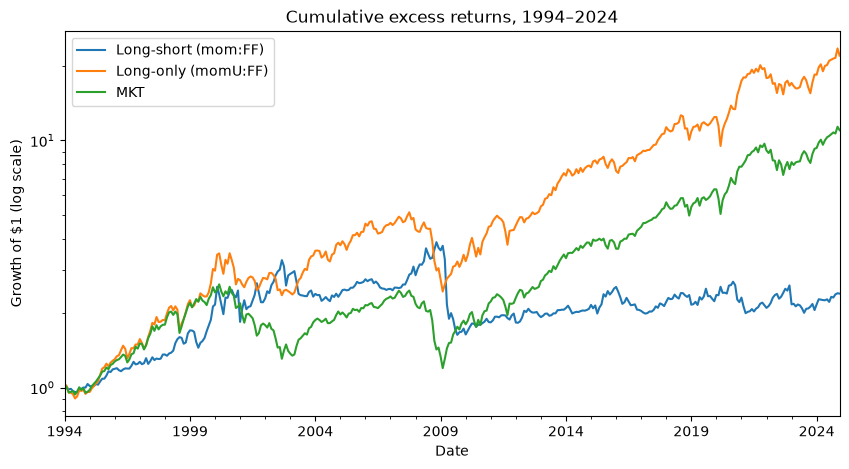

Long-short (mom:FF)     2.40
Long-only (momU:FF)    22.02
MKT                    10.99
Name: 2024-12-31 00:00:00, dtype: float64

In [6]:
cum = pd.DataFrame({"Long-short (mom:FF)": long_short, "Long-only (momU:FF)": long_only, "MKT": mkt}).add(1).cumprod()

cum.plot(logy=True, figsize=(10, 5), title="Cumulative excess returns, 1994–2024")
plt.ylabel("Growth of $1 (log scale)")
plt.show()

cum.iloc[-1].round(2)

Long-only moves with the market, with the same ups and downs, and ends about twice as high ($22 vs $11 per $1). Long-short follows its own path: it grows to about $3.9 by late 2008, drops to $1.7 in the 2009 crash, and has been roughly flat since, ending at $2.4.

## 2.3 Is momentum data mining or a robust strategy?

Sample: 1994–2024. Long-short constructions, equal-weighted across included deciles:
- $\tilde{r}^{\text{momD1}}$: top 1 decile minus bottom 1 decile
- $\tilde{r}^{\text{momD3}}$: top 3 deciles minus bottom 3 deciles
- $\tilde{r}^{\text{momD5}}$: top 5 deciles minus bottom 5 deciles

### (a)
Fill in Table 3 for $\tilde{r}^{\text{momD1}}$, $\tilde{r}^{\text{momD3}}$, $\tilde{r}^{\text{momD5}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [7]:
d = deciles.loc[s:e]
mom_d1 = d["D10"] - d["D1"]
mom_d3 = d[["D8", "D9", "D10"]].mean(axis=1) - d[["D1", "D2", "D3"]].mean(axis=1)
mom_d5 = d[["D6", "D7", "D8", "D9", "D10"]].mean(axis=1) - d[["D1", "D2", "D3", "D4", "D5"]].mean(axis=1)

table3 = pd.DataFrame({"momD1": stats(mom_d1, mkt, hml), "momD3": stats(mom_d3, mkt, hml),
                       "momD5": stats(mom_d5, mkt, hml), "mom:FF": stats(long_short, mkt, hml)}).T
display(table3.style.format(FMT))
print(f"worst month: momD1 {mom_d1.min():.1%}, momD3 {mom_d3.min():.1%}, momD5 {mom_d5.min():.1%}")

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
momD1,8.10%,29.96%,0.27,-1.30,-0.32,-0.24
momD3,2.97%,19.37%,0.15,-1.34,-0.36,-0.21
momD5,1.73%,13.43%,0.13,-1.42,-0.35,-0.21
mom:FF,4.31%,16.72%,0.26,-1.46,-0.31,-0.21


worst month: momD1 -45.3%, momD3 -35.6%, momD5 -24.9%


### (b)
Do the tradeoffs across the 1-, 3- and 5-decile constructions match the theory from lecture?

**Answer:**

Yes. The more selective the sort, the further apart the winners and losers are, so the mean goes up: 8.1% for the 1-decile spread, 3.0% for 3 deciles and 1.7% for 5. But fewer stocks means less diversification, so volatility goes up too: 30% vs 19% vs 13%. The correlations with MKT and HML barely change across the three.

The effect gets weaker smoothly as you widen the sort, instead of only working for one particular cutoff. That's what a real effect looks like, not data mining.

### (c)
Should AQR's retail product use a 1-decile or a 5-decile construction?

**Answer:**

On paper the 1-decile version wins: it has the best Sharpe (0.27 vs 0.15 and 0.13) with about the same correlations. For a retail product I'd still go wider, something like the 3-decile version. The 1-decile portfolio has 30% volatility and a worst month of −45%, which most retail investors won't sit through. It also trades the most, so its Sharpe edge, which is measured before costs, is the most likely to disappear. The 5-decile version goes too far the other way: a 1.7% mean is easy for costs to wipe out.

### (d)
Compare $\tilde{r}^{\text{momD3}}$ with the FF construction in Table 2. Both are 3-decile long-short, but FF separates small and large stocks.

**Answer:**

FF momentum does better than momD3: a higher mean (4.3% vs 3.0%), lower volatility (16.7% vs 19.4%) and a Sharpe of 0.26 vs 0.15. The difference is the size split. The deciles are value-weighted, so momD3 is mostly big stocks. FF builds winners and losers separately within small and big stocks and gives each half equal weight, so small stocks, where momentum is stronger (2.4), get 50% of the weight.

## 2.4 Does implementation require trading many small stocks?

Sample: 1994–2024.
- Small-stock momentum: $r^{\text{momS}} = r^{\text{momSU}} - r^{\text{momSD}}$
- Big-stock momentum: $r^{\text{momB}} = r^{\text{momBU}} - r^{\text{momBD}}$

### (a)
Fill in Table 4 for all stocks, small stocks and large stocks: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$.

In [8]:
z = size.loc[s:e]
mom_small = z["SMALL HiPRIOR"] - z["SMALL LoPRIOR"]
mom_big   = z["BIG HiPRIOR"] - z["BIG LoPRIOR"]

table4 = pd.DataFrame({"All stocks": stats(long_short, mkt, hml), "Small stocks": stats(mom_small, mkt, hml),
                       "Large stocks": stats(mom_big, mkt, hml)}).T.drop(columns="Corr to HML")
display(table4.style.format(FMT))
print(f"share of the FF momentum mean coming from the small half: {0.5 * mom_small.mean() / long_short.mean():.0%}")

,Mean,Vol,Sharpe,Skewness,Corr to MKT
All stocks,4.31%,16.72%,0.26,-1.46,-0.31
Small stocks,6.14%,16.91%,0.36,-1.80,-0.31
Large stocks,2.46%,18.23%,0.14,-0.87,-0.28


share of the FF momentum mean coming from the small half: 71%


### (b)
Is momentum's attractiveness driven mostly by small stocks, or does large-stock momentum still offer comparable risk-adjusted excess returns?

**Answer:**

Mostly by small stocks. Small-stock momentum earns 6.1% a year with a Sharpe of 0.36, against 2.5% and 0.14 for large stocks, with similar volatility (16.9% vs 18.2%). So the gap is in the returns, not the risk, and about 71% of the FF momentum mean comes from the small half.

Large-stock momentum doesn't offer comparable risk-adjusted returns, but it does crash less (skewness −0.87 vs −1.80). And small stocks are the expensive ones to trade, so some of their edge would go to costs.

## 2.5 Conclusion

Assess the AQR retail product. Does it capture the key features of the FF momentum construction? What modifications would you suggest?

**Answer:**

AQR's retail product is long-only, holds roughly the top third of large and mid-cap stocks by momentum, is value-weighted, and rebalances quarterly. It keeps the momentum signal, but it loses the two things that made FF momentum attractive.

First, the hedge. Without the short side, its correlation with the market goes from −0.31 to +0.90 (2.2), and that negative correlation was the main reason to hold momentum (2.1). Second, the small-cap part. Value-weighting and a large/mid-cap universe leave out where momentum is strongest (a Sharpe of 0.36 for small vs 0.14 for large stocks, 2.4).

What it does well is keep costs down. Quarterly rebalancing and a broad top-third cutoff mean much less trading than the FF portfolio, whose paper returns ignore costs.

I'd suggest two changes: add a small short leg (something like 130/30) to get back part of the hedge, and weight more toward mid and smaller caps (equal or capped weights) as far as liquidity allows.